Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Make sure you fill in any place that says `YOUR CODE HERE` or "YOUR ANSWER HERE", as well as your name and collaborators below:

In [1]:
NAME = "Ruilin Yang"
COLLABORATORS = "Claude, OpenAI"

---

# Problem description

Satellites orbiting the Earth take photos that private companies sell to customers. A financial analyst might extract information from these photos that helps predict the future price of a stock, for example:

- Approximate number of customers visiting each store: count the cars in the parking lot
- Approximate activity in a factory: count supplier trucks arriving and delivery trucks leaving
- Approximate demand for a commodity: count cargo ships traveling between ports

In this assignment we will recognize **ships in satellite photos**: a first step toward counting.
We ignore domain-specific knowledge and just use a labeled training set (a photo plus a binary indicator for whether a ship is present), assuming the labels are perfect.

This is the same problem as the earlier *Ships in satellite images* assignment, where you used Logistic Regression.
This time you will use a **neural network**, and you will run a set of experiments to build intuition for how
the **number of layers** and the **width** of the layers affect the model.

## Goal

Build and compare **Dense** (fully-connected) neural-network classifiers for satellite photos.

- The features are images: 80 x 80 pixels (we will convert to gray scale and flatten, exactly as in the Logistic Regression assignment)
- The labels are 1 (ship is present) or 0 (ship is not present)

## Learning objectives
- See that a neural network with no hidden layer *is* Logistic Regression
- Count the parameters of a Dense network
- Build intuition for the effect of depth (number of layers, $L$) and width (units per layer) on accuracy and on the gap between in-sample and out-of-sample performance
- Practice disciplined model selection: choose on a validation set, touch the test set once

## This is a checkpoint assignment
It verifies that you can build, train and compare neural networks. It is not meant to be a puzzle.
Most of the work is running experiments and **thinking about what you see**.

## Grading
The required parts are worth **200 points**. You can earn up to **100 additional points** for going above and beyond: the optional extensions at the end of the notebook and any further experiments of your own. In the required parts, written answers are graded on whether they are consistent with **your own results** and give specific support (a number from your table or a named configuration), not on length. Optional work is graded on whether it ran, on what you conclude from it, and on how carefully you handled the noise.

## How to run this notebook

**Toolkit:** use any neural-network toolkit you like (Keras with any backend, TensorFlow, PyTorch, ...).
Everything you are asked to *report* is toolkit-independent (numbers, tables, short written answers).

**Hardware:** you do **not** need a GPU. The whole notebook should run in a few minutes on an ordinary laptop CPU.

**Running locally:** put `helper.py` and the data file `shipsnet.json` next to this notebook (the data may also be in a `Data/` folder).

**Running on Google Colab:** (optional, but fine)
- Upload `helper.py` to **the same directory as your notebook**
- **Recommended: put `shipsnet.json` (344 MB) on your own Google Drive, once.** Upload it to `My Drive/Colab Notebooks/Data/` (from drive.google.com or a Colab session) and mount the Drive in a cell (`from google.colab import drive; drive.mount('/content/drive')`; Google will ask for your permission). The helper looks in `Colab Notebooks/Data` and `Data` on your Drive automatically; if you used another folder, set `DATA_DIR` (next cell group) to the folder that contains `shipsnet.json`
- Uploading `shipsnet.json` to the Colab session through the *Files* panel also works in principle, but it is a 344 MB upload (slow, and it can fail on a poor connection) and the file disappears whenever the runtime is recycled, so you would have to upload it again
  - If the data is on your Drive in another folder, set `DATA_DIR` (next cell group) to the folder that contains `shipsnet.json`
  - If the notebook itself is on your Drive, mount the Drive and `%cd` into the folder that contains the notebook and `helper.py`

# Imports

In [2]:
## Standard imports
import os
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from IPython.display import display

%matplotlib inline

In [3]:
## Are we running on Colab?
try:
  from google.colab import drive
  IN_COLAB=True
except:
  IN_COLAB=False

if IN_COLAB:
  print("We're running Colab")

In [4]:
## Where is the data?
# Leave as None if shipsnet.json is next to this notebook (or in ./Data).
# Otherwise set it to the folder that contains shipsnet.json, e.g. (Colab + Google Drive):
#   drive.mount('/content/drive')
#   DATA_DIR = "/content/drive/MyDrive/my_folder"
DATA_DIR = None

In [5]:
## Load the helper module
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

# Optional convenience: pick up edits to helper.py without restarting the kernel.
# (Not available on every Python/IPython combination, e.g. Colab's, so failure is fine.)
try:
    get_ipython().run_line_magic("reload_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "1")
    AUTORELOAD = True
except Exception:
    AUTORELOAD = False

import helper
if AUTORELOAD:
    get_ipython().run_line_magic("aimport", "helper")

helper = helper.Helper(data_dir=DATA_DIR)

In [6]:
## Import your neural-network toolkit here (plus anything else you need)
# Tip (TensorFlow/Keras): the harmless C++ log messages can be silenced by setting
#   os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   before importing keras/tensorflow
# YOUR CODE HERE
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
tf.config.set_visible_devices([], "GPU")   # use CPU only: reproducible results
import keras
from keras import layers

#raise NotImplementedError()

# API for students

`helper.py` defines a class `Helper`; `helper = helper.Helper()` creates one.

- `getData`: get a collection of labeled images

  >`data, labels = helper.getData()`
- `showData`: visualize labeled images

  >`helper.showData(data, labels)`
- `showWeights`: visualize weight vectors as images (used in an *optional* part at the end)

  >`helper.showWeights(W)`

# Get the data

The first step in our Recipe is Get the Data. (Loading the 344 MB file takes 20 to 30 seconds.)

In [7]:
# Get the data
data, labels = helper.getData()
n_samples, width, height, channel = data.shape

print("Data shape: ", data.shape)
print("Labels shape: ", labels.shape)
print("Label values: ", np.unique(labels))

Data shape:  (4000, 80, 80, 3)
Labels shape:  (4000,)
Label values:  [0 1]


Your expected outputs should be the following

`Data shape: (4000, 80, 80, 3)`
`Labels shape: (4000,)`
`Label values: [0 1]`

We shuffle the examples before doing anything else (the file may be ordered by label).

In [8]:
# Shuffle the data first
data, labels = sklearn.utils.shuffle(data, labels, random_state=42)

## Have a look at the data
We will not go through all steps in the Recipe, nor in depth. But here's a peek.

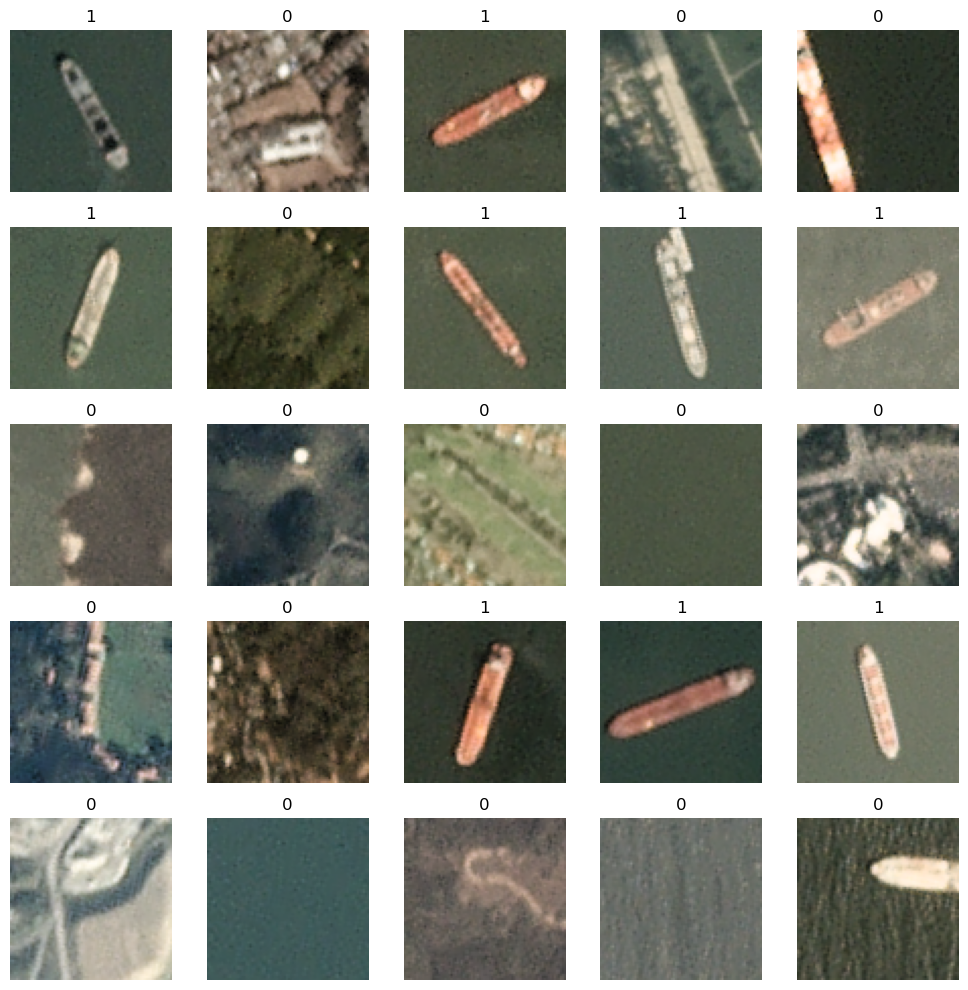

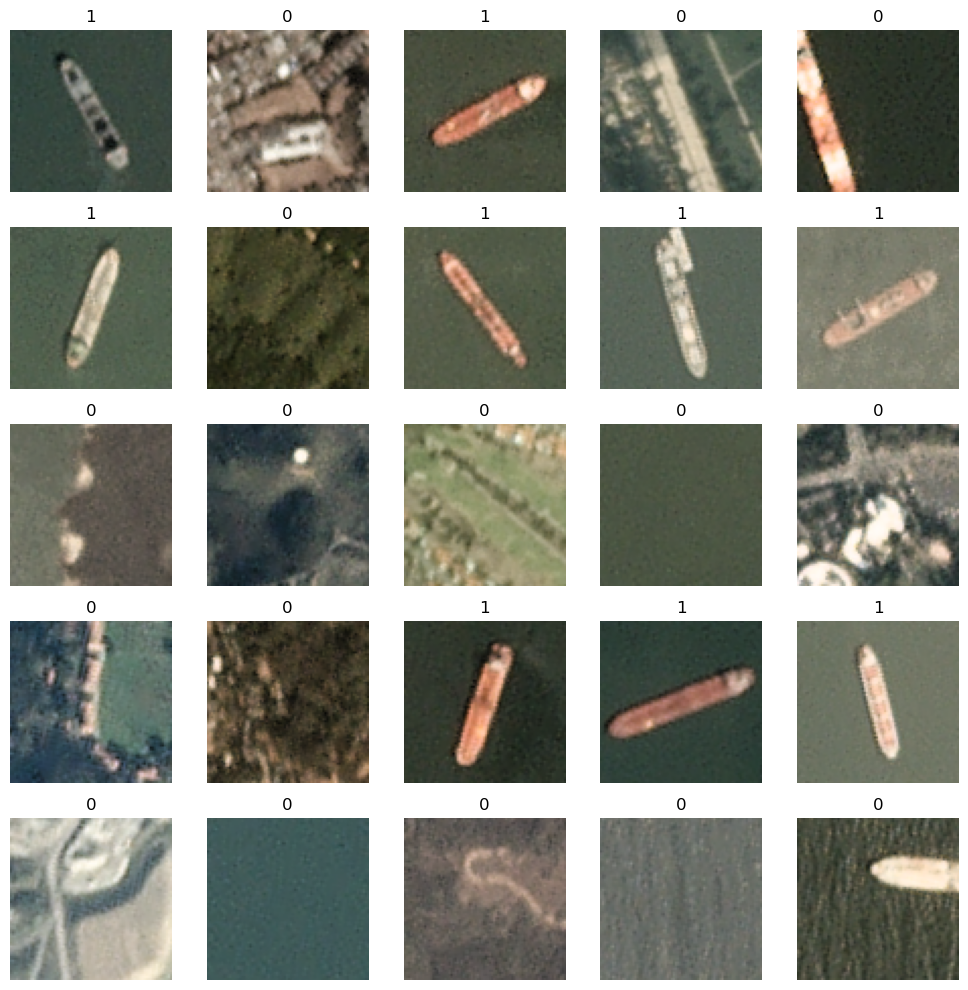

In [9]:
# Visualize some samples
helper.showData(data[:25], labels[:25])

## Eliminate the color dimension and flatten
As in the Logistic Regression assignment, we convert to gray scale.
Then we **flatten** each 80 x 80 image into a vector of 6400 numbers, since a Dense layer takes a vector as input.

In [10]:
print("Original shape of data: ", data.shape)

w = (.299, .587, .114)
data_bw = np.sum(data * w, axis=3)

# Flatten each image: (N, 80, 80) --> (N, 6400)
X = data_bw.reshape(data_bw.shape[0], -1)
y = labels

print("New shape of data: ", data_bw.shape)
print("Flattened X shape: ", X.shape)

Original shape of data:  (4000, 80, 80, 3)
New shape of data:  (4000, 80, 80)
Flattened X shape:  (4000, 6400)


## Split the data: train / validation / test

In the Logistic Regression assignment you split 90% / 10% (train / test).
Here you will run **many** experiments and *choose among them*. If you chose using the test set, the test accuracy of the model you
chose would be optimistic (you would have "trained on the test set" by selection).
So we carve out a **validation** set to choose with, and we touch the **test** set only **once**, at the very end.

**Question:** create `X_train, X_val, X_test, y_train, y_val, y_test` as follows:
- First split off 10% of the examples as the **test** set, with `random_state=42`
  - (This is exactly the same test set as in the Logistic Regression assignment)
- Then split the remaining 90% into train and validation so that the **validation** set has 400 examples (that is, 1/9 of what remains), with `random_state=42`

You should end up with 3200 training, 400 validation and 400 test examples.

In [11]:
from sklearn.model_selection import train_test_split

# Create X_train, X_val, X_test, y_train, y_val, y_test
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=400, random_state=42)
#1/9 of 3600 = 400. BUT 1/9 = 0.1111, possible result of 401
#raise NotImplementedError()

print("X_train shape: ", X_train.shape)
print("X_val shape:   ", X_val.shape)
print("X_test shape:  ", X_test.shape)

# Self-check (given): sizes, and number of ships in each set
print("ships in train/val/test:", int(y_train.sum()), int(y_val.sum()), int(y_test.sum()))
assert (X_train.shape[0], X_val.shape[0], X_test.shape[0]) == (3200, 400, 400)
assert (int(y_train.sum()), int(y_val.sum()), int(y_test.sum())) == (812, 101, 87), "Right sizes but different examples: follow the order of the two splits described above"


X_train shape:  (3200, 6400)
X_val shape:    (400, 6400)
X_test shape:   (400, 6400)
ships in train/val/test: 812 101 87


Your expected outputs should be the following

`X_train shape:  (3200, 6400)`
`X_val shape:    (400, 6400)`
`X_test shape:   (400, 6400)`

## Standardize

**Question:** standardize the pixels (mean 0, standard deviation 1 per pixel position), as you did before.
- Fit a `StandardScaler` named `scaler` on the **training** examples only
- Create `X_train_s`, `X_val_s`, `X_test_s`: the scaled versions of the three sets

(From here on, every model in this notebook uses these scaled arrays.)

In [12]:
from sklearn.preprocessing import StandardScaler

# YOUR CODE HERE
scaler = StandardScaler().fit(X_train) #ONLY for Train Data
X_train_s = scaler.transform(X_train).astype("float32")
X_val_s   = scaler.transform(X_val).astype("float32")
X_test_s  = scaler.transform(X_test).astype("float32")
#raise NotImplementedError()

---
# Part 1: The Logistic Regression baseline

Re-create the baseline from the earlier assignment so that we have something to compare the neural networks against.

**Question:**
- Fit an `sklearn` `LogisticRegression(solver="liblinear")` on the scaled training examples. Name it `lr_clf`.
- Set `lr_train_acc` and `lr_val_acc` to its accuracy on the training and validation examples
- Set `lr_num_params` to its **total** number of learnable parameters (**including** the intercept)

*(Do not evaluate on the test set yet.)*

Sanity check: the validation accuracy should land between about 0.82 and 0.90.

In [13]:
from sklearn.linear_model import LogisticRegression

# YOUR CODE HERE
lr_clf = LogisticRegression(solver="liblinear").fit(X_train_s, y_train)
lr_train_acc = lr_clf.score(X_train_s, y_train)
lr_val_acc   = lr_clf.score(X_val_s, y_val)
lr_num_params = lr_clf.coef_.size + lr_clf.intercept_.size   # 6400 weights + 1 intercept
#raise NotImplementedError()

print("Logistic Regression: train acc={a:.3f}, validation acc={v:.3f}, #parameters={p:d}".format(
    a=lr_train_acc, v=lr_val_acc, p=lr_num_params))

Logistic Regression: train acc=1.000, validation acc=0.855, #parameters=6401


---
# Part 2: A Dense network with no hidden layer

Define **$L$ = the number of *hidden* layers**. The output layer is not counted.

The simplest Dense classifier has $L = 0$: the 6400 inputs connect directly to a single output unit with a **sigmoid** activation,
trained with **binary cross-entropy** loss.

## The training recipe (the same for *every* network in this notebook)

So that differences between experiments come from the **architecture** and not from the training procedure, always use:

> **Read this table before you write any code, and check your code against it afterwards.** Every row is part of the experiment. The **random seed** and **batch shuffling** rows are the two that are easiest to get wrong, and they matter for the noise questions later.

| Setting | Value |
|---|---|
| Loss | binary cross-entropy |
| Optimizer | Adam, learning rate 0.001 |
| Batch size | 64 |
| Epochs | 30 (always train all 30; no early stopping) |
| Hidden-layer activation | ReLU |
| Initialization, other optimizer settings | your toolkit's defaults |
| Output layer | 1 unit, sigmoid |
| **Random seed** | `SEED` (below). Set it the way your toolkit does, e.g. `keras.utils.set_random_seed(SEED)` or `torch.manual_seed(SEED)`. Results are then reproducible on your machine but can differ slightly on other machines |
| Inputs | the standardized gray-scale vectors `X_train_s`, ... |
| **Batches** | **shuffle the training examples every epoch** (reshuffle, not one fixed order); keep the last, smaller batch |
| Reported accuracy | evaluate the **final trained model** on the whole set (not a running average printed during training) |

**Before you rely on `SEED`:** work out what in *your* toolkit's training code is random, and check that your seed setting really controls all of it. Optional C asks you to write this down.

An example is predicted to have a ship when the output probability is greater than 0.5; *accuracy* is the fraction of examples predicted correctly.

In [14]:
SEED = 0
EPOCHS = 30
BATCH_SIZE = 64
LEARNING_RATE = 1e-3

**Question:** build and train the $L=0$ network on the training examples, using the recipe.
- Name the model `model_L0`
- Set `L0_num_params` to the number of parameters of `model_L0` (your toolkit can report this)
- Set `L0_train_acc` and `L0_val_acc` to its final accuracy on the training and validation examples

In [15]:
# YOUR CODE HERE
def build_model(hidden_widths, n_inputs=6400):
    """Dense ReLU hidden layers + 1 sigmoid output, compiled with the recipe."""
    model = keras.Sequential(
        [keras.Input(shape=(n_inputs,))]
        + [layers.Dense(w, activation="relu") for w in hidden_widths]
        + [layers.Dense(1, activation="sigmoid")]
    )
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

def train_model(hidden_widths, seed=SEED):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)      # seeds Python, NumPy and the backend
    model = build_model(hidden_widths)
    model.fit(X_train_s, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
              shuffle=True, verbose=0)     # reshuffles each epoch, keeps last partial batch
    return model

def accuracy(model, X, y):
    """Accuracy of the FINAL model on the whole set (threshold 0.5)."""
    p = np.asarray(model(X, training=False)).ravel()
    return float(np.mean((p > 0.5) == y))

model_L0 = train_model([])
L0_num_params = model_L0.count_params()
L0_train_acc  = accuracy(model_L0, X_train_s, y_train)
L0_val_acc    = accuracy(model_L0, X_val_s, y_val)

#raise NotImplementedError()

print("L=0 network: train acc={a:.3f}, validation acc={v:.3f}, #parameters={p:d}".format(
    a=L0_train_acc, v=L0_val_acc, p=L0_num_params))

L=0 network: train acc=0.942, validation acc=0.858, #parameters=6401


**Question (written):** Compare the $L=0$ network with the Logistic Regression of Part 1.
- Why is a Dense network with no hidden layer, one sigmoid output and binary cross-entropy loss "the same model" as Logistic Regression? Compare the number of parameters.
- Are the accuracies identical? Compare the **training** accuracies as well as the validation accuracies. If they differ, give a reason the two could differ even though the model family is the same (hint: look at the default settings of `LogisticRegression`, and at how each model was trained). A reasoned hypothesis is enough; you do not have to test it.

YOUR ANSWER HERE

**Question 1**: Why is a Dense network with no hidden layer, one sigmoid output, and binary cross-entropy loss "the same model" as Logistic Regression? Compare the number of parameters.

Answer.
* Both have 6401 parameters: 6400 weight parameters + 1 bias parameter
    * Both have one weight per pixel plus one bias.
* Same Model Family 
    * x feature; w weight; b bias
    * sigmoid function: $\sigma(z)=1/(1+e^{-z})$
      
    * L=0 network computes $\hat{y} = \sigma(w^{T}·x + b)$
    * Logistic Regression: P(ship | x) = $\sigma(w^{T}·x + b)$
    * Same Objective Function: Both optimize the same binary cross-entropy loss (aka log-loss)
    * Same decision rule: p>0.5 = ship, else: no ship 


**Question 2**: Are the accuracies identical? Compare the **training** accuracies as well as the validation accuracies. If they differ, give a reason the two could differ even though the model family is the same (hint: look at the default settings of `LogisticRegression`, and at how each model was trained). A reasoned hypothesis is enough; you do not have to test it.

Answer: 
The accuracies are not identical: 
* Logistic Regression: training accuracy = 1.000, validation accuracy = 0.855
* L=0 network:         training accuracy = 0.942, validation accuracy = 0.858

Reason: 
- Regularization: Both use binary cross-entropy as their data-fitting loss. However, sklearn’s Logistic Regression adds an L2 penalty by default, while this network has no weight penalty, so their complete training objectives differ.

- Optimizer and stopping point: Logistic Regression uses Liblinear, which optimizes until its stopping tolerance or iteration limit is reached, while the L=0 network stops after exactly 30 Adam epochs.

---
# Part 3: Count parameters, then run the experiments

Now add hidden layers. Use hidden layers that all have the **same width** (number of units): `hidden_widths = [w] * L`.

## Count the parameters by hand first

A Dense layer with `n_in` inputs and `n_out` units has `n_in * n_out` weights plus `n_out` biases.

**Question:** write `count_dense_params(hidden_widths, n_inputs=6400)`, which returns the total number of parameters of a Dense network
with the given list of hidden-layer widths followed by a **single** sigmoid output unit. For example `hidden_widths=[]` is the $L=0$ network.
Compute it from the formula above: **do not build a model to get the answer**.

In [16]:
def count_dense_params(hidden_widths, n_inputs=6400):
    """Number of parameters of a Dense network: n_inputs -> hidden_widths[0] -> ... -> hidden_widths[-1] -> 1"""
    # YOUR CODE HERE
    sizes = [n_inputs] + list(hidden_widths) + [1]
    return sum(n_in * n_out + n_out for n_in, n_out in zip(sizes[:-1], sizes[1:]))

    #raise NotImplementedError()

assert count_dense_params([]) == L0_num_params, "L=0 should match your toolkit's count"
print("L=0:", count_dense_params([]))

L=0: 6401


## One function to run an experiment

**Question:** write `run_experiment(hidden_widths, seed=SEED)` that
1. builds a Dense network with the given hidden widths (ReLU) and a single sigmoid output unit,
2. trains it with the recipe on `X_train_s, y_train`,
3. returns a dictionary with keys `"model"`, `"num_params"` (reported by your toolkit), `"train_acc"` and `"val_acc"` (final accuracy on the training and validation examples).

Set the random seed at the start so that the experiment is reproducible.

In [17]:
def run_experiment(hidden_widths, seed=SEED):
    # YOUR CODE HERE
    model = train_model(hidden_widths, seed)
    return {"model": model,
            "num_params": model.count_params(),
            "train_acc": accuracy(model, X_train_s, y_train),
            "val_acc":   accuracy(model, X_val_s, y_val)}
    #raise NotImplementedError()

# Sanity check: with no hidden layers this should reproduce Part 2
info = run_experiment([])
print("L=0 via run_experiment: train acc={a:.3f}, val acc={v:.3f}, #parameters={p:d}".format(
    a=info["train_acc"], v=info["val_acc"], p=info["num_params"]))

L=0 via run_experiment: train acc=0.942, val acc=0.858, #parameters=6401


## The experiment grid

Run **every combination** of
- $L \in \{1, 2, 3\}$ hidden layers
- width $\in \{4, 16, 64, 256\}$ units in each hidden layer

That is 12 networks. For each, record the number of parameters, the training accuracy and the validation accuracy.

**Question:** create a `pandas` DataFrame named `results` with one row per experiment and the columns
`L`, `width`, `num_params`, `train_acc`, `val_acc`; also add a first row for the $L=0$ network (use `width = 0`).
Before you run each experiment, compute `count_dense_params` and **assert** that it equals the number of parameters your toolkit reports.

**Notes**
- Expect a few minutes on a laptop CPU in total (the widest networks are the slowest). It's a good idea to print progress as you go.
- If your machine is far too slow, you may drop width 256 *and say so explicitly* in your answers.
- Don't tune anything: the recipe is fixed so that only $L$ and width change.
- **Noise:** training a network involves randomness (initial weights, batch order), and the validation set has only 400 examples.
  Differences in accuracy of **about 1.5 percentage points or less are within noise**. Don't read meaning into them.
  The very narrowest networks can be especially erratic from one run to another. Expect an outlier or two in your grid (a configuration that dips for no obvious reason). If you see one, say so in your answers instead of building a story around it.

In [18]:
rows = []

# L = 0 baseline row (from Part 2)
rows.append(dict(L=0, width=0, num_params=L0_num_params, train_acc=L0_train_acc, val_acc=L0_val_acc))

# YOUR CODE HERE
for L in [1, 2, 3]:
    for w in [4, 16, 64, 256]:
        hw = [w] * L
        expected = count_dense_params(hw)            # computed by hand, before training
        t0 = time.time()
        info = run_experiment(hw)
        assert expected == info["num_params"], (hw, expected, info["num_params"])
        rows.append(dict(L=L, width=w, num_params=info["num_params"],
                         train_acc=info["train_acc"], val_acc=info["val_acc"]))
        print("L={L} width={w:>3}: params={p:>9,d} train={a:.3f} val={v:.3f} ({t:.0f}s)".format(
            L=L, w=w, p=info["num_params"], a=info["train_acc"], v=info["val_acc"], t=time.time() - t0))

#raise NotImplementedError()

results = pd.DataFrame(rows)
results

L=1 width=  4: params=   25,609 train=0.985 val=0.915 (4s)
L=1 width= 16: params=  102,433 train=1.000 val=0.968 (11s)
L=1 width= 64: params=  409,729 train=0.998 val=0.960 (16s)
L=1 width=256: params=1,638,913 train=1.000 val=0.963 (23s)
L=2 width=  4: params=   25,629 train=0.923 val=0.850 (3s)
L=2 width= 16: params=  102,705 train=0.999 val=0.955 (4s)
L=2 width= 64: params=  413,889 train=0.996 val=0.975 (6s)
L=2 width=256: params=1,704,705 train=1.000 val=0.968 (16s)
L=3 width=  4: params=   25,649 train=0.978 val=0.907 (4s)
L=3 width= 16: params=  102,977 train=0.995 val=0.945 (4s)
L=3 width= 64: params=  418,049 train=1.000 val=0.973 (6s)
L=3 width=256: params=1,770,497 train=0.998 val=0.975 (38s)


,L,width,num_params,train_acc,val_acc
0,0,0,6401,0.942187,0.8575
1,1,4,25609,0.985313,0.9150
2,1,16,102433,1.000000,0.9675
3,1,64,409729,0.997500,0.9600
4,1,256,1638913,0.999687,0.9625
5,2,4,25629,0.923125,0.8500
6,2,16,102705,0.999375,0.9550
7,2,64,413889,0.996250,0.9750
8,2,256,1704705,1.000000,0.9675
9,3,4,25649,0.977812,0.9075


## Look at the results

The next cells (already written) plot your `results`.

,L,width,num_params,train_acc,val_acc,gap
0,0,0,6401,0.942,0.858,0.085
1,1,4,25609,0.985,0.915,0.070
2,1,16,102433,1.000,0.968,0.032
3,1,64,409729,0.998,0.960,0.038
4,1,256,1638913,1.000,0.962,0.037
5,2,4,25629,0.923,0.850,0.073
6,2,16,102705,0.999,0.955,0.044
7,2,64,413889,0.996,0.975,0.021
8,2,256,1704705,1.000,0.968,0.032
9,3,4,25649,0.978,0.908,0.070


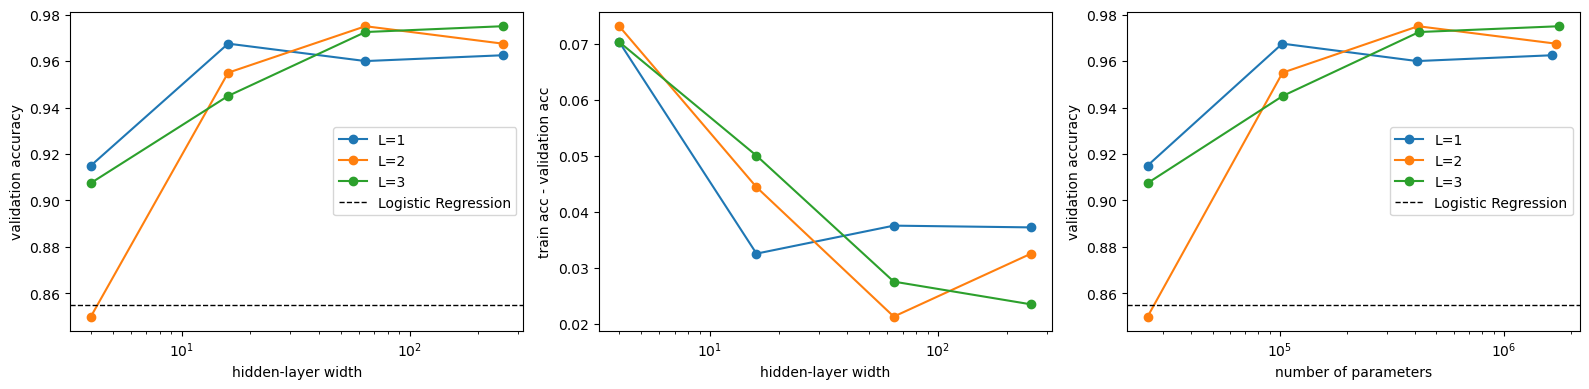

In [19]:
results["gap"] = results["train_acc"] - results["val_acc"]
display(results.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for L, grp in results[results.L > 0].groupby("L"):
    axes[0].plot(grp.width, grp.val_acc, marker="o", label="L={L}".format(L=L))
    axes[1].plot(grp.width, grp.gap, marker="o", label="L={L}".format(L=L))
    axes[2].plot(grp.num_params, grp.val_acc, marker="o", label="L={L}".format(L=L))
for ax in axes[:2]:
    ax.set_xscale("log"); ax.set_xlabel("hidden-layer width")
axes[2].set_xscale("log"); axes[2].set_xlabel("number of parameters")
axes[0].set_ylabel("validation accuracy"); axes[1].set_ylabel("train acc - validation acc"); axes[2].set_ylabel("validation accuracy")
axes[0].axhline(lr_val_acc, color="k", ls="--", lw=1, label="Logistic Regression")
axes[2].axhline(lr_val_acc, color="k", ls="--", lw=1, label="Logistic Regression")
axes[0].legend(); axes[2].legend()
fig.tight_layout();

**Questions (written).** Use your table and plots, and remember the noise warning. A short paragraph per question is plenty; refer to specific rows of your table.

1. **Width.** What happens to validation accuracy as width increases (for a fixed $L$)? Is there a point of diminishing returns?
2. **Depth.** What happens as $L$ increases (for a fixed width)? Does depth matter as much as width?
3. **Parameters.** Which grows the number of parameters faster, adding width or adding a layer? Explain using your parameter formula (which term dominates?).
4. **Where do the parameters go?** (a) Pick two configurations with the **same width** but different $L$: how different are their parameter counts, and how different are their accuracies? (b) Pick two configurations whose parameter counts differ by a **large factor** (say 10x or more) and compare their accuracies. What do you conclude about spending parameters on depth versus on width?
5. **In-sample versus out-of-sample.** How does the training accuracy compare with the validation accuracy? How does the gap change with $L$ and width? Compare the number of parameters with the number of training examples (3200). (What you see may surprise you; say what you make of it.)
6. **Versus Logistic Regression.** Does any network clearly beat Logistic Regression? By how much, and is that larger than the noise?

YOUR ANSWER HERE
1. **WIDTH** Increase width --> increase the accuracy of results
| Hidden layers (\(L\)) | Width 4 | Width 16 | Width 64 | Width 256 |
|---|---:|---:|---:|---:|
| 1 | 91.5% | 96.8% | 96.0% | 96.2% |
| 2 | 85.0% | 95.5% | 97.5% | 96.8% |
| 3 | 90.8% | 94.5% | 97.2% | 97.5% |

    * Diminishing returns: after width 16 for L=1, and after width 64 for L=2 and L=3
    * No configuration gains from going to width 256.
    
2. **DEPTH** increase L --> doesn't increase validation accuracy 
| Hidden-layer width | \(L=1\) | \(L=2\) | \(L=3\) |
|---|---:|---:|---:|
| 4 | 91.5% | 85.0% | 90.8% |
| 16 | 96.8% | 95.5% | 94.5% |
| 64 | 96.0% | 97.5% | 97.2% |
| 256 | 96.2% | 96.8% | 97.5% |

    * Width helps more consistently than depth in this run.
    * Changing the width from 4 to 16 moves accuracy by 4–10 points, while changing depth moves it by 2.3 points or less, apart from the outlier.

3. **PARMETERS**
For L>=1: $P=(6400+1)w+(L-1)(w+1)w+(w+1)$ = 6400·w + w (first layer) + (L−1)(w² + w) (other hidden layers) + w + 1 (output)
   - Most parameters connect the 6,400 inputs to the first hidden layer.
   - Increasing width adds many parameters because every new first-layer neuron needs 6,400 input weights.
   - Adding one hidden layer adds only \(w^2+w\) parameters.
   - Example: at \(L=1\), increasing width from 4 to 256 raises the count from 25,609 to 1,638,913—about 64 times as many.
   - Therefore, in this experiment, increasing width grows the parameter count faster than adding depth.

4. **Where do the parameters go?** 

**(A) Same width, different depth(L)**
    * Width 256, L=1 vs L=3: 1,638,913 vs 1,770,497 parameters, only 8% more. Validation is 0.963 vs 0.975, 1.25 points apart, which is within noise.
    * Width 64, L=1 vs L=2: 409,729 vs 413,889 parameters, only 1% more. Validation is 0.960 vs 0.975, 1.5 points apart, right at the edge of noise.
    * Depth is nearly free in parameters, and it didn’t produce a reliable accuracy gain
  
      
**(B) Large parameter difference**
    * L=1: width 16 (102,433) vs width 256 (1,638,913), 16× more parameters. Validation is 0.968 vs 0.963, so the larger model is no better.
    * L=1, width 16 vs L=3, width 256 (1,770,497), 17× more. Validation is 0.968 vs 0.975, +0.75 points, which is noise.

**Conclusion**
    - Most parameters connect the inputs to the first hidden layer.
    - For \(L=1\), widening beyond 16 units provides no clear validation improvement.
    - For \(L=2\) and \(L=3\), increasing width from 16 to 64 helps in this run.
    - Adding depth costs relatively few parameters, but its effect on accuracy is inconsistent.
    - More parameters do not guarantee better validation accuracy.


5. **In-sample versus out-of-sample.**
   * **Accuracy:** Networks with width 16 or more achieve about 99.5–100% training accuracy, versus 94.5–97.5% validation accuracy.
   * **Gap:** shrinks as width increases; depth doesn't show a clear pattern in the gap:
   
         * L=0 has the largest gap at 8.5 points.
         * Width 4 decreases by about 7 points (0.070, 0.073, 0.070) 
         * Width 16 decreases by 3–5 points.
         * Widths 64 and 256 decrease by about 2–4 points (smallest is L=2, width 64 at 2.1).
   
   * **Number of Parameters:** even the smallest network (25,609 parameters) has 8× more parameters than the 3,200 training examples. The largest (1,770,497) has about 550× more
   * **Suprise:** Despite having more parameters, wider networks generally have smaller gaps and better validation accuracy.
   * **Say what you make of it:** Parameter count alone does not determine overfitting. Wider networks may learn more useful features, and the training procedure may favor solutions that generalize. These are possible explanations, not proven conclusions.


6. **Versus Logistic Regression.**
   - Baseline: Logistic Regression achieves 85.5% validation accuracy.
   - Best networks: L=2, w=64 and L=3, w=256 achieve 97.5%—12 percentage points higher, or 48 more correct predictions.
   - Small networks also improve: L=1, w=4 reaches 91.5%, while L=3, w=4 reaches about 90.8%.
   - Exception:  L=2, w=4 scores 85.0%, essentially tied with Logistic Regression under the noise guideline.
   - No hidden layers: L=0 scores about 85.8%, only 0.25 percentage points higher using the unrounded result—well within the 1.5-point guideline.
   - Conclusion: Most networks with hidden layers substantially outperform Logistic Regression in this run.

---
# Part 4: Choose a model, then use the test set once

**Question:**
- Choose the configuration (`best_L`, `best_width`) among the 12 networks with at least one hidden layer ($L \geq 1$; the $L=0$ row is **not** a candidate).
  Count the correct validation predictions of each: `n_correct = round(val_acc * 400)`. Let `top` be the largest `n_correct` among them. Every configuration with `n_correct >= top - 6` is a candidate (6 examples is 1.5 points of 400; counting examples avoids floating-point ties); of these, choose the one with the **fewest parameters**.
- Train that configuration with `run_experiment` and evaluate it on the **test** set: set `test_acc`.
- Also set `lr_test_acc`, the test accuracy of your Logistic Regression `lr_clf`.

This is the **only** time in this notebook you may evaluate on the test set.

Because of noise, your chosen configuration may differ from a classmate's; what matters is that it follows the rule when applied to **your** table.

In [20]:
# YOUR CODE HERE
cand = results[results.L >= 1].copy()
cand["n_correct"] = (cand["val_acc"] * len(y_val)).round().astype(int)
top = cand["n_correct"].max()
cand = cand[cand["n_correct"] >= top - 6]            # within 1.5 points of the best
display(cand)
best = cand.loc[cand["num_params"].idxmin()]         # fewest parameters among the candidates
best_L, best_width = int(best["L"]), int(best["width"])

best_info = run_experiment([best_width] * best_L)
test_acc    = accuracy(best_info["model"], X_test_s, y_test)    # the only use of the test set
lr_test_acc = lr_clf.score(X_test_s, y_test)

#raise NotImplementedError()

print("Chosen network: L={L}, width={w}".format(L=best_L, w=best_width))
print("Test accuracy: chosen network={n:.3f}, Logistic Regression={l:.3f}".format(n=test_acc, l=lr_test_acc))

,L,width,num_params,train_acc,val_acc,gap,n_correct
2,1,16,102433,1.000000,0.9675,0.032500,387
3,1,64,409729,0.997500,0.9600,0.037500,384
4,1,256,1638913,0.999687,0.9625,0.037187,385
7,2,64,413889,0.996250,0.9750,0.021250,390
8,2,256,1704705,1.000000,0.9675,0.032500,387
11,3,64,418049,1.000000,0.9725,0.027500,389
12,3,256,1770497,0.998437,0.9750,0.023438,390


Chosen network: L=1, width=16
Test accuracy: chosen network=0.960, Logistic Regression=0.855


**Questions (written):**
1. Is the test accuracy of your chosen network similar to its validation accuracy? Would you expect it to be a little lower, and why?
2. The hidden layers raise accuracy substantially over Logistic Regression, which uses the same inputs. **Propose a hypothesis** for *why* (think about what a single set of 6400 weights, one per pixel, can and cannot express, compared with several hidden units that are then combined).
   Then say what **evidence** you could collect to support or refute it. (You do not have to collect it; Optional A below shows one way.)

YOUR ANSWER HERE

1. Validation versus test
    * Validation accuracy is 96.75% (387/400), versus 96.0% (384/400) on the test.
    * The difference is only 3 examples, or 0.75 percentage points, so the results are similar.
    * Validation accuracy may be slightly optimistic because it was used to select the model. The untouched test set provides an independent performance check.
    * Logistic Regression achieves 85.5% on the test, so the network improves accuracy by 10.5 percentage points

2. Why hidden layers may help
    * **Hypothesis**: Logistic Regression uses one weighted combination of pixels. Hidden units with ReLU can learn several patterns and combine them into a more flexible decision rule. This may help recognize ships with different appearances, orientations, or positions.
    * **Support from my table**: For L=1, validation accuracy rises from about 85.8% with no hidden layer, to 91.5% with 4 units, to 96.8% with 16 units, then levels off.
    * **Evidence to collect**: Plot the 16 first-layer weight images and inspect which images activate each unit. Compare errors across ship orientations and positions. Consistent improvements over Logistic Regression would support the hypothesis; weight pictures alone are insufficient.

---
# Optional extensions

These are optional, but they are how you earn the additional 100 points. They also build intuition.

## Optional A: Look at the first-layer weights

In the Logistic Regression assignment you plotted the learned coefficients as an 80 x 80 image (`model_interpretation`): there is one coefficient per pixel,
so the coefficients form a "template" the model matches.

**Task:**
1. Train a network with one hidden layer of 16 units (`run_experiment([16])`)
2. Extract the weight matrix of its **first** layer: 6400 weights for each of the 16 units
3. Use `helper.showWeights(W)` to show each unit's 6400 weights as an 80 x 80 image (`W` has shape `(6400, 16)`; your toolkit may store the transpose)
4. Also show the Logistic Regression coefficients with `helper.showWeights(lr_clf.coef_[0])`

**Written:** What do you see? Compare with the single Logistic Regression template.
Then: **why does this kind of picture only make sense for the first layer** of a network? What would the weights of the *second* layer be indexed by, and could you reshape them into a picture of pixels?

W shape: (6400, 16)  val acc: 0.9675


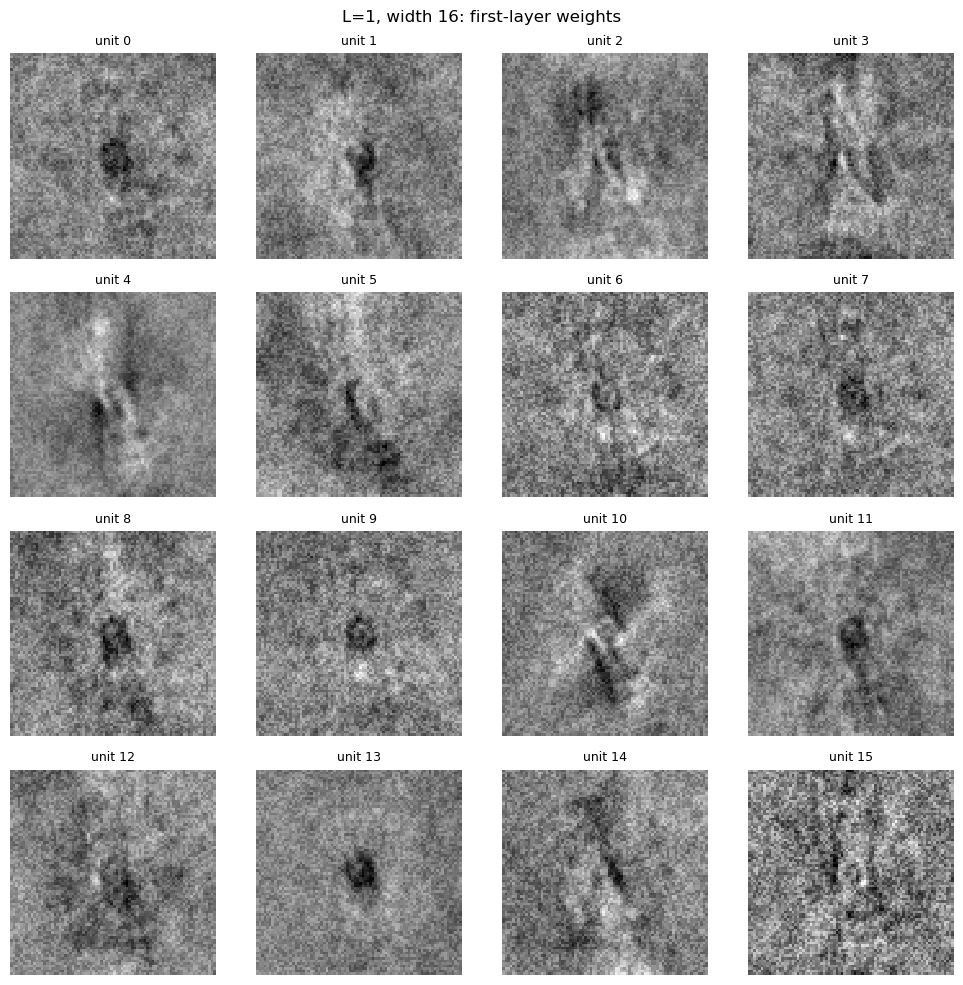

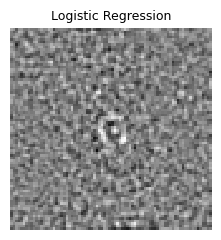

In [21]:
# YOUR CODE HERE (optional)
info16 = run_experiment([16])
W = info16["model"].layers[0].get_weights()[0]        # shape (6400, 16)
print("W shape:", W.shape, " val acc:", info16["val_acc"])
helper.showWeights(W, suptitle="L=1, width 16: first-layer weights");
helper.showWeights(lr_clf.coef_[0], titles=["Logistic Regression"]);

YOUR ANSWER HERE
* See: 16 hidden units have a smooth structure concentrated in the center of the image, where the ship sits in positive examples in various formats:
    * unit 0, 1,9, 11, 13 - Compact dark blobs at the center
    * unit 7,8,9 lighter Compact dark blobs at the center
    * unit 2,4,5,10,14 - long diagonal
    * Bit faint: 3,12,6 
    * Most noise: unit 15
* Logistic regression: pure high-frequency speckle, with only a tiny faint ring at the center. It might ignore ship images that don't look like compact dark blobs at the center
* The network instead learns several different detectors, such as blobs and bars at different angles, and combines them, which allows more varied ships to be identified. Therefore, it increases accuracy compared (like in the basic section of the homework)
* Why only the first layer:
  * First-layer weights are indexed by (pixel, unit). Unit k has one weight per input pixel (6,400 of them), so they reshape to 80 × 80.
  * Second-layer weights are indexed by (first-layer unit i, second-layer unit j). With width 16, each second-layer unit has 16 weights, one per first-layer unit, and none for pixels.

## Optional B: Non-constant widths ("funnels") and minimum widths

So far every hidden layer had the same width. Try networks whose layers have **different** widths, such as `[2, 256]`, `[256, 2]`, `[4, 256]`, `[256, 4]`, compared with `[2, 2]`, `[4, 4]` and `[256, 256]`.
(Use `run_experiment`, which already accepts any list of widths. Single runs are noisy, so consider averaging a few seeds.)

**Written:** Is there a *minimum* width for a layer, below which making the *other* layers wider doesn't help?
Does it matter whether the narrow layer comes first or later? Why might that be? (Think about what the first layer must do with 6400 inputs, versus what a later layer receives.)

In [22]:
# YOUR CODE HERE (optional)
configs = [[2, 2], [2, 256], [256, 2], [4, 4], [4, 256], [256, 4], [256, 256]]
rows_b = []
for hw in configs:
    runs = [run_experiment(hw, seed=s) for s in [0, 1, 2]]
    train_accs = [r["train_acc"] for r in runs]
    val_accs   = [r["val_acc"] for r in runs]
    rows_b.append(dict(widths=str(hw), num_params=count_dense_params(hw),
                       train_mean=np.mean(train_accs),
                       val_mean=np.mean(val_accs), val_std=np.std(val_accs, ddof=1)))
    print(hw, "done")
display(pd.DataFrame(rows_b).round(4))

[2, 2] done
[2, 256] done
[256, 2] done
[4, 4] done
[4, 256] done
[256, 4] done
[256, 256] done


,widths,num_params,train_mean,val_mean,val_std
0,"[2, 2]",12811,0.9451,0.8825,0.0156
1,"[2, 256]",13827,0.9609,0.8875,0.0066
2,"[256, 2]",1639173,0.9708,0.9383,0.0166
3,"[4, 4]",25629,0.9691,0.9000,0.0458
4,"[4, 256]",27141,0.9721,0.9175,0.0087
5,"[256, 4]",1639689,0.9767,0.9425,0.0175
6,"[256, 256]",1704705,1.0000,0.9683,0.0014


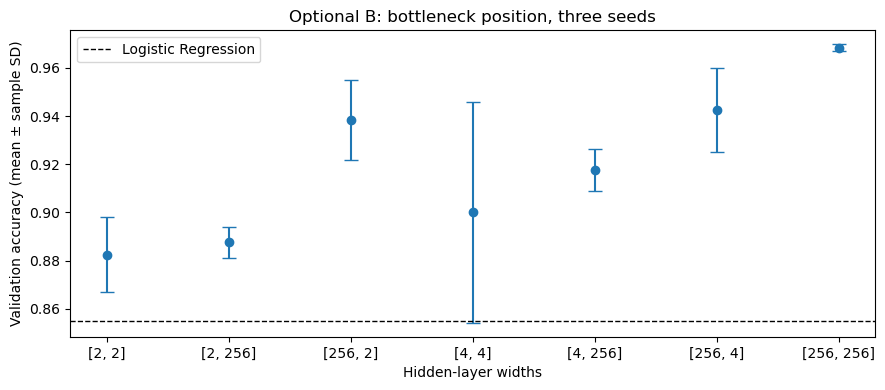

In [23]:
dfb = pd.DataFrame(rows_b)
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(dfb["widths"], dfb["val_mean"], yerr=dfb["val_std"], fmt="o", capsize=5)
ax.axhline(lr_val_acc, color="k", ls="--", lw=1, label="Logistic Regression")
ax.set_xlabel("Hidden-layer widths"); ax.set_ylabel("Validation accuracy (mean ± sample SD)")
ax.set_title("Optional B: bottleneck position, three seeds"); ax.legend()
fig.tight_layout();

YOUR ANSWER HERE
* **Minimum width for a layer:** These results suggest that a very narrow first layer can limit performance.
    * With width 2 first, widening the second layer improves the mean by only 0.5 percentage points.
    * With width 4 first, the improvement is 1.75 points, but [4, 4] varies substantially across seeds.
    * This suggests a bottleneck, but does not establish an exact minimum width.
* **Who comes first?:** A narrow later layer still limits performance: [256, 4] trails [256, 256] by about 2.6 points.
    * [256, 2] beats [2, 256] by about 5.1 points.
    * [256, 4] beats [4, 256] by 2.5 points.
* Why? (given only two layer) 
    * A narrow first layer compresses 6,400 pixels into just 2–4 activations. Later layers cannot recover information that this mapping discards.
    * A narrow second layer receives learned features rather than raw pixels, which may make useful information easier to retain.
* **Caution**: Three seeds provide limited evidence. The results support a bottleneck interpretation, but comparing a difference with one model’s SD alone does not establish whether the gain is reliable

## Optional C: Measure the noise

Repeat the whole grid with **three different seeds** (e.g., `seed=0,1,2` passed to `run_experiment`). Report the **mean and (sample) standard deviation** of validation accuracy for each configuration.
Redo the comparison from Part 3: which of your earlier conclusions survive once you see the spread?

**Written:** (1) List every place in *your* training code where randomness enters. For each, say whether your seed setting controls it, and how you checked (for example, same seed twice, different seeds). (2) In an experiment with "several seeds", should the train/validation split also change from seed to seed? Say what each choice would measure.

In [24]:
# YOUR CODE HERE (optional)
# reproducibility check: same seed twice must match, different seeds should differ
a = run_experiment([16], seed=0)["val_acc"]; b = run_experiment([16], seed=0)["val_acc"]
c = run_experiment([16], seed=1)["val_acc"]
print("seed 0 twice:", a, b, " seed 1:", c)

rows_c = []
for L in [1, 2, 3]:
    for w in [4, 16, 64, 256]:
        accs = [run_experiment([w] * L, seed=s)["val_acc"] for s in [0, 1, 2]]
        rows_c.append(dict(L=L, width=w, seed0=accs[0], seed1=accs[1], seed2=accs[2],
                           val_mean=np.mean(accs), val_std=np.std(accs, ddof=1)))
        print("L={} width={} done".format(L, w))
noise = pd.DataFrame(rows_c)
display(noise.round(4))
display(noise.pivot(index="L", columns="width", values="val_mean").round(3))

seed 0 twice: 0.9675 0.9675  seed 1: 0.9475
L=1 width=4 done
L=1 width=16 done
L=1 width=64 done
L=1 width=256 done
L=2 width=4 done
L=2 width=16 done
L=2 width=64 done
L=2 width=256 done
L=3 width=4 done
L=3 width=16 done
L=3 width=64 done
L=3 width=256 done


,L,width,seed0,seed1,seed2,val_mean,val_std
0,1,4,0.9150,0.9050,0.8925,0.9042,0.0113
1,1,16,0.9675,0.9475,0.9450,0.9533,0.0123
2,1,64,0.9600,0.9600,0.9550,0.9583,0.0029
3,1,256,0.9625,0.9575,0.9575,0.9592,0.0029
4,2,4,0.8500,0.9400,0.9100,0.9000,0.0458
5,2,16,0.9550,0.9575,0.9550,0.9558,0.0014
6,2,64,0.9750,0.9675,0.9800,0.9742,0.0063
7,2,256,0.9675,0.9700,0.9675,0.9683,0.0014
8,3,4,0.9075,0.8950,0.9025,0.9017,0.0063
9,3,16,0.9450,0.9200,0.9550,0.9400,0.0180


width,4,16,64,256
L,,,,
1,0.904,0.953,0.958,0.959
2,0.900,0.956,0.974,0.968
3,0.902,0.940,0.966,0.977


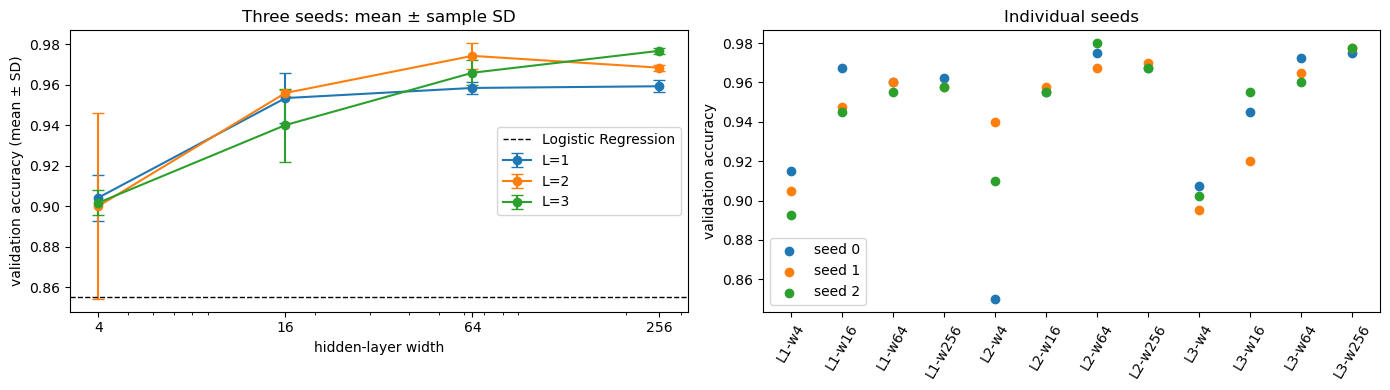

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# Left: mean ± SD vs width, one line per L
for L, grp in noise.groupby("L"):
    axes[0].errorbar(grp["width"], grp["val_mean"], yerr=grp["val_std"],
                     marker="o", capsize=4, label="L={}".format(L))
axes[0].set_xscale("log"); axes[0].set_xticks([4, 16, 64, 256]); axes[0].set_xticklabels([4, 16, 64, 256])
axes[0].axhline(lr_val_acc, color="k", ls="--", lw=1, label="Logistic Regression")
axes[0].set_xlabel("hidden-layer width"); axes[0].set_ylabel("validation accuracy (mean ± SD)")
axes[0].set_title("Three seeds: mean ± sample SD"); axes[0].legend()
# Right: every individual seed, to show the spread
labels = ["L{}-w{}".format(L, w) for L, w in zip(noise.L, noise.width)]
for s in [0, 1, 2]:
    axes[1].scatter(labels, noise["seed{}".format(s)], label="seed {}".format(s))
axes[1].tick_params(axis="x", rotation=60)
axes[1].set_ylabel("validation accuracy"); axes[1].set_title("Individual seeds"); axes[1].legend()
fig.tight_layout();

YOUR ANSWER HERE
* Width 4 → 16 is a large jump: survives.
    *  L=1: 0.904 → 0.953.
    *  L=2: 0.900 → 0.956.
    *  L=3: 0.902 → 0.940.
* Diminishing returns past width 16 at L=1: survives. Widths 16, 64 and 256 score 0.953, 0.958 and 0.959, all within noise.
* Depth sometimes helps: 
    * At widths 64 and 256, deeper networks are slightly but consistently better:
        * Width 64: L=1 = 0.958 ± 0.003 vs L=2 = 0.974 ± 0.006.
        * Width 256: L=1 = 0.959 ± 0.003 vs L=3 = 0.977 ± 0.001.
        * That’s about +1.5–1.8 points, with small SDs
    * At width 16, L=3 is lower (0.940 ± 0.018), but its spread is large.
* Narrow networks can be unstable: L=2, w=4 scores 85%, 94%, and 91%, with a sample SD of about 4.6 points. The original low score was not representative of every run.
* Seed 0 was above average: The selected network scored 96.75%, versus a three-seed mean of about 95.3%. This shows training variability; it does not by itself prove selection bias.

**Written**
* Randomness entered:
    * Initial weights and batch shuffling: Controlled by keras.utils.set_random_seed(seed)
    * Image shuffle and data splits: Fixed separately by random_state=42.
    * Logistic Regression: Fitted once as the baseline; it was not part of the three-seed neural-network comparison.
    * Numerical computation: Seeds alone do not guarantee identical floating-point results across environments
    * Check: Repeating seed 0 reproduced 96.75% accuracy; seed 1 gave 94.75%. Matching accuracy supports reproducibility, but does not establish identical weights or predictions.
      

* Should the split change?:
    * Keep it fixed: Measures variation from initialization and training order on the same validation examples.
    * Change train/validation splits: Also measures sensitivity to which examples enter each set. Refit the scaler on each training split.
    * Changing splits measures broader variability, but does not guarantee a larger observed SD.
    * Keep the final test set fixed and outside these experiments.

## Optional D: Sparse weights with L1 regularization

Logistic Regression's default penalty (L2) shrinks weights but leaves almost all of them nonzero, which is partly why its weight image looks like noise. An **L1** penalty pushes most weights to zero (for Logistic Regression's solver they become exactly zero; with a gradient-based optimizer such as Adam they become tiny but not exactly zero).

**Task:**
1. Fit `LogisticRegression(solver="liblinear", penalty="l1", C=...)` for a few values of `C` (try 0.1, 0.02, 0.005; smaller `C` means a stronger penalty). For each, report the validation accuracy and the fraction of nonzero weights, and show the weight images with `helper.showWeights`. (Recent versions of scikit-learn print a harmless warning about the `penalty` argument.)
2. Add an L1 penalty to the **first layer only** of a network with one hidden layer of 16 units (Keras: `kernel_regularizer=regularizers.l1(lam)`; PyTorch: add `lam * W.abs().sum()` to the loss). Try `lam` in 1e-5, 1e-4, 1e-3. Compare the first-layer weight images and the validation accuracy with the unregularized network. Report the fraction of first-layer weights with absolute value below 0.001. (`helper.showWeights` gives each picture its own color scale, so a unit whose weights are all tiny looks like speckle; pass `shared_scale=True` to compare pictures on one scale.)

**Written:** Does the sparse picture make the "template" easier to read? What does it cost in accuracy? Is a cleaner picture evidence of a better model?

LR L1 C=0.1: val acc=0.8800, nonzero weights=3.39%


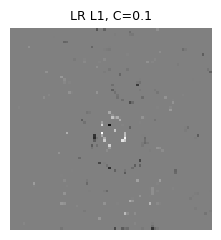

LR L1 C=0.02: val acc=0.8550, nonzero weights=1.03%


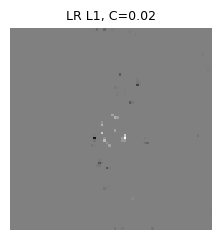

LR L1 C=0.005: val acc=0.8125, nonzero weights=0.44%


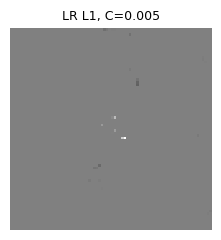

NN L1 lam=0.0: val acc=0.9675, |w|<0.001: 2.83%


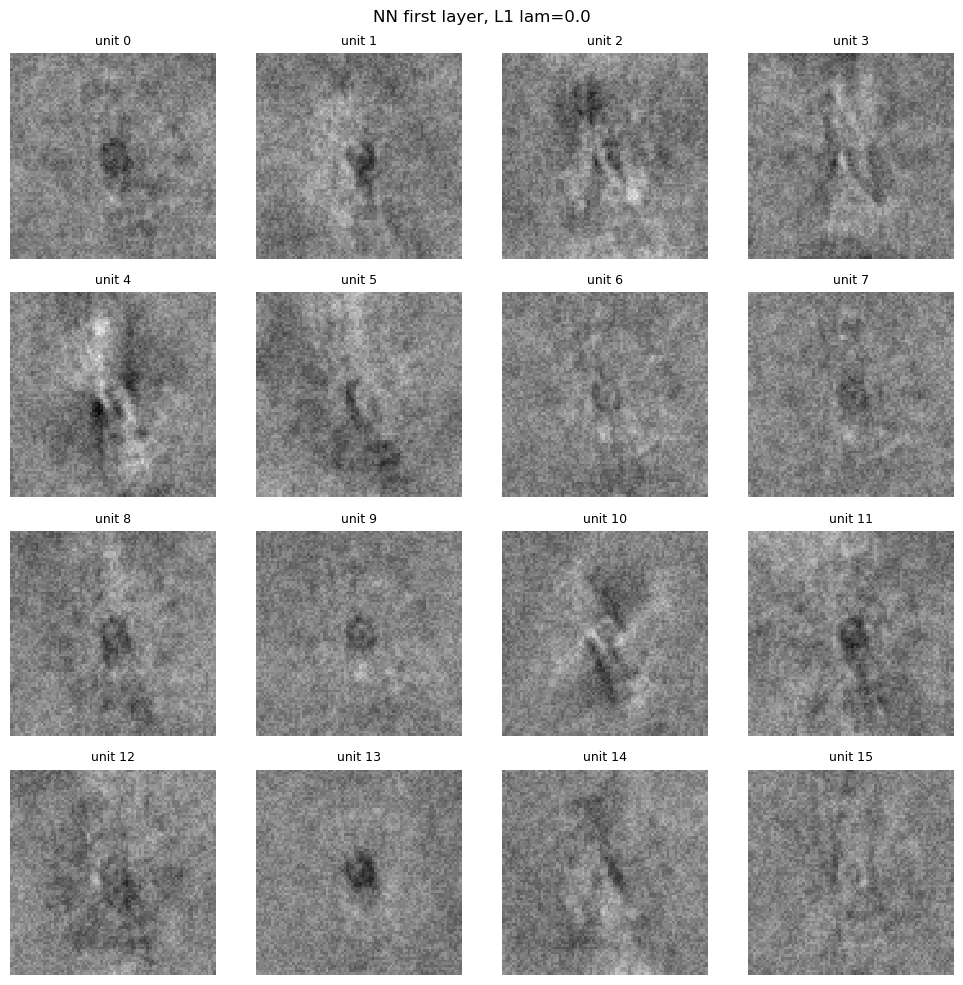

NN L1 lam=1e-05: val acc=0.9675, |w|<0.001: 9.09%


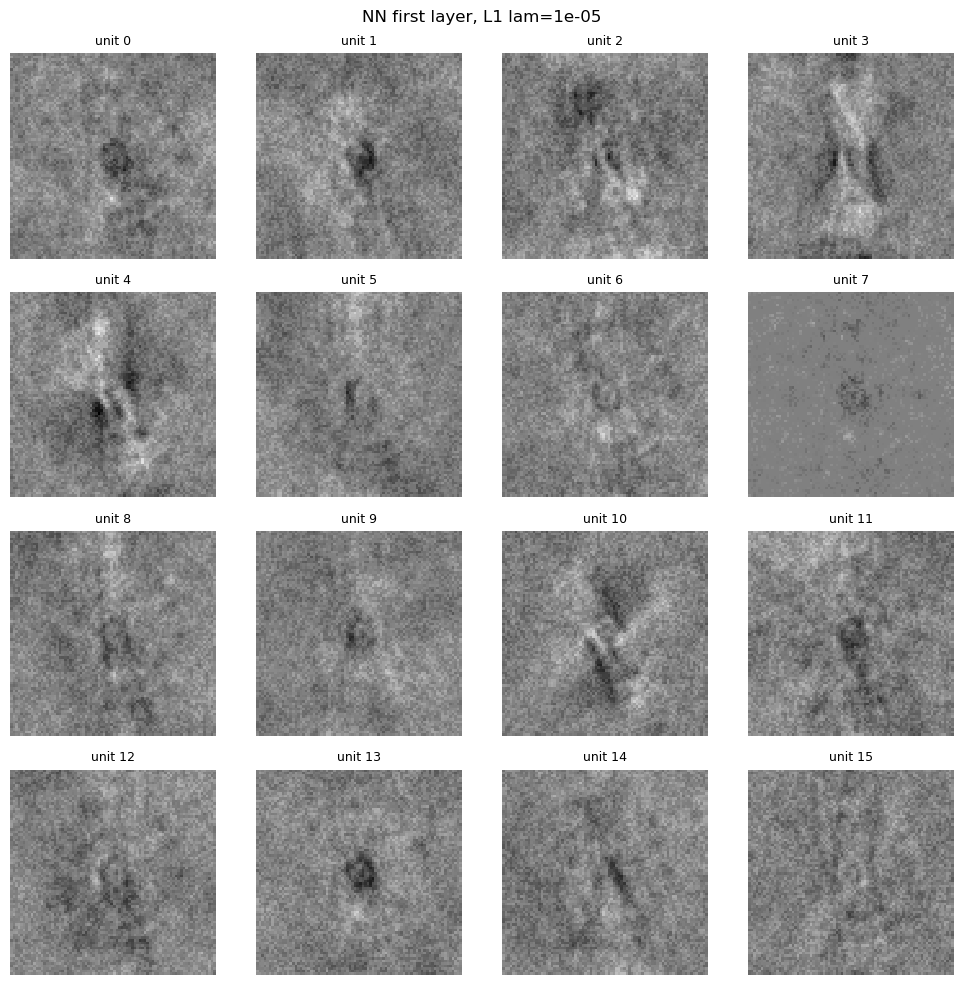

NN L1 lam=0.0001: val acc=0.9450, |w|<0.001: 18.79%


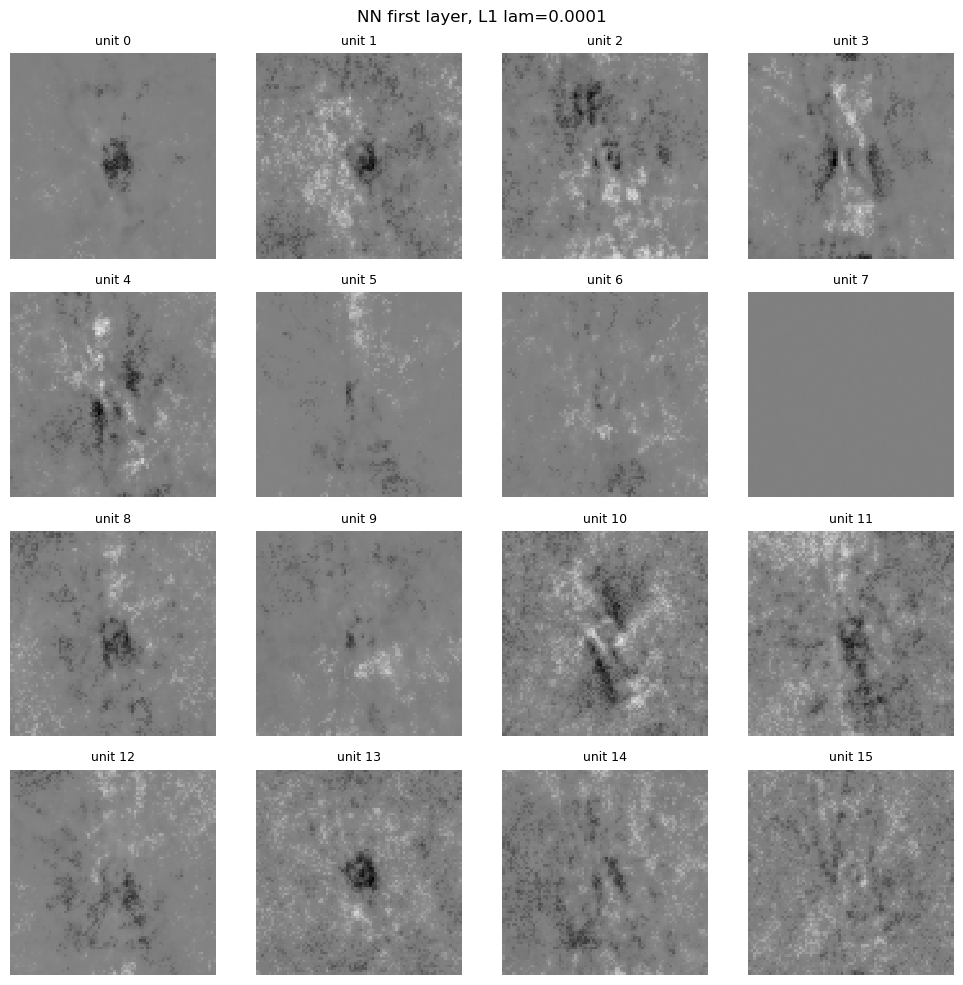

NN L1 lam=0.001: val acc=0.9425, |w|<0.001: 78.30%


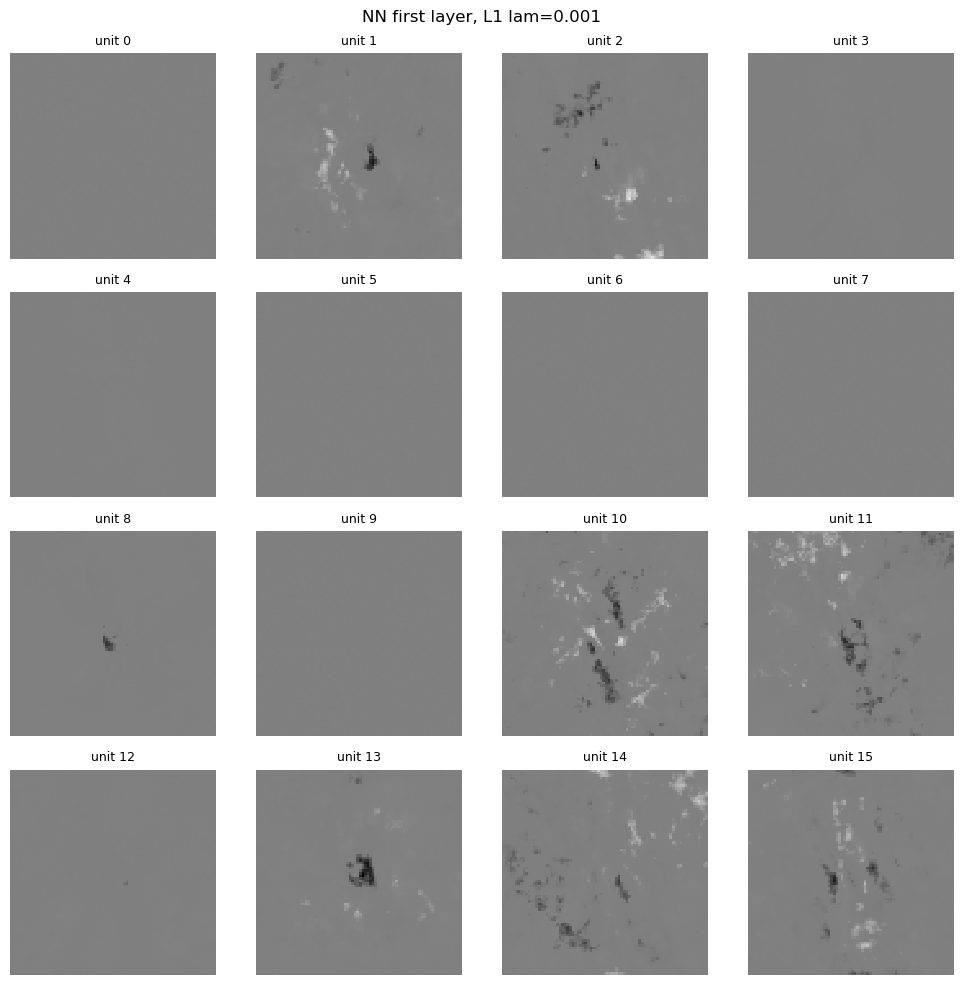

,model,setting,val_acc,nonzero,small_weights
0,LR L1,C=0.1,0.8800,0.0339,NaN
1,LR L1,C=0.02,0.8550,0.0103,NaN
2,LR L1,C=0.005,0.8125,0.0044,NaN
3,NN [16] L1,lam=0.0,0.9675,NaN,0.0283
4,NN [16] L1,lam=1e-05,0.9675,NaN,0.0909
5,NN [16] L1,lam=0.0001,0.9450,NaN,0.1879
6,NN [16] L1,lam=0.001,0.9425,NaN,0.7830


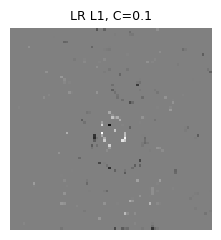

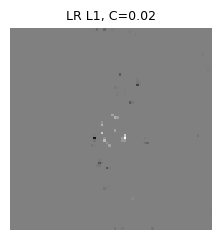

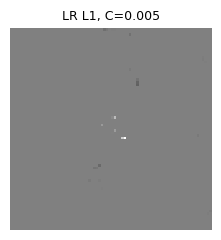

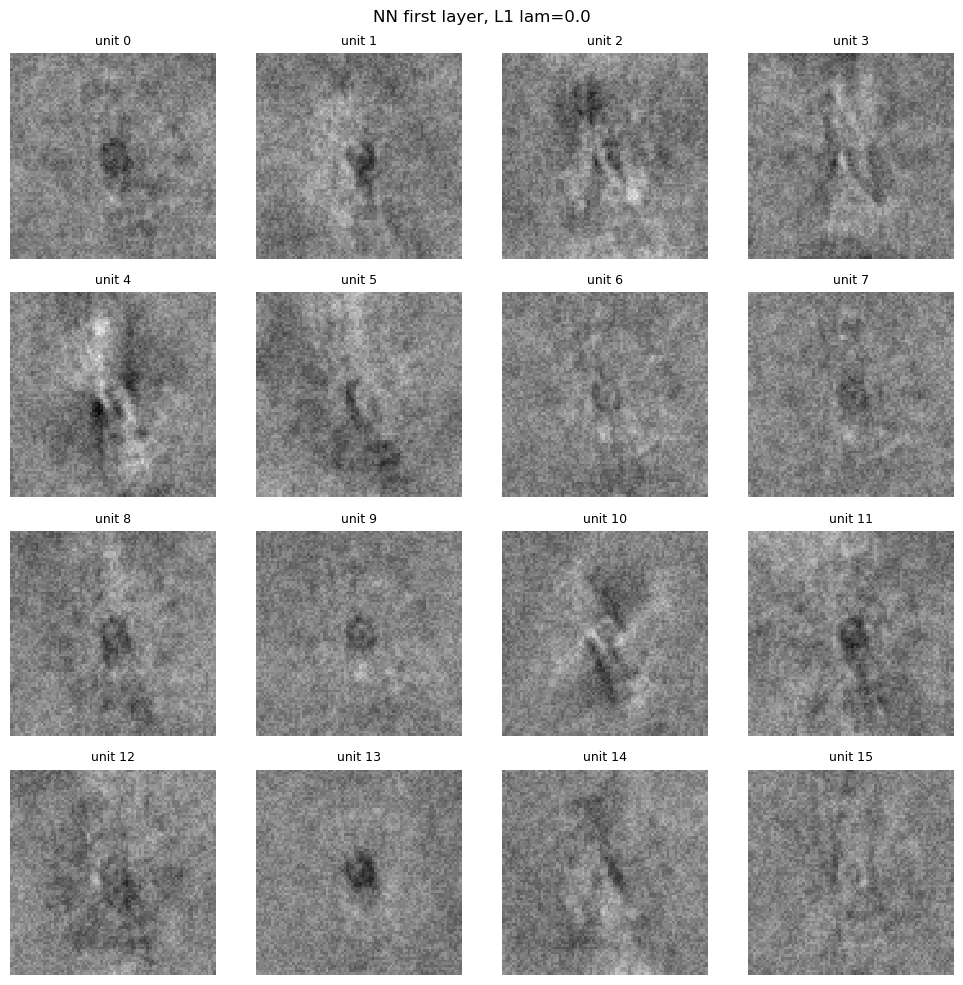

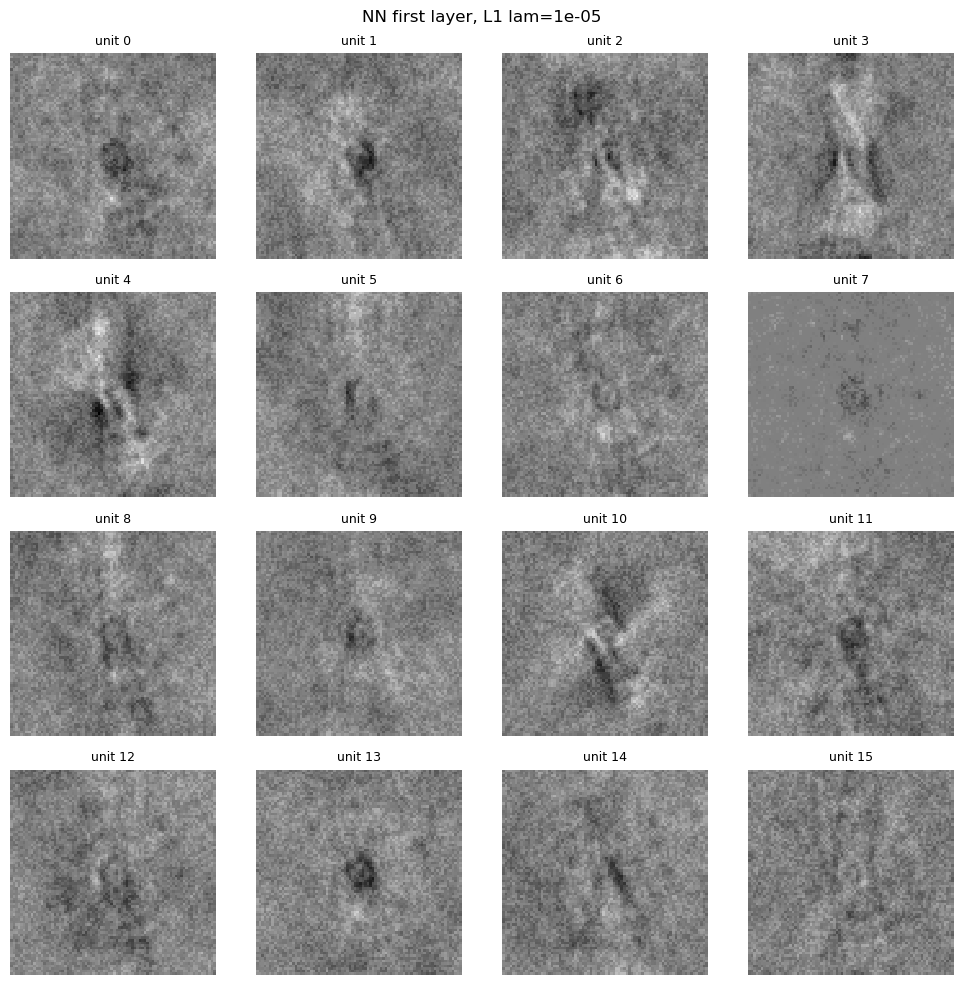

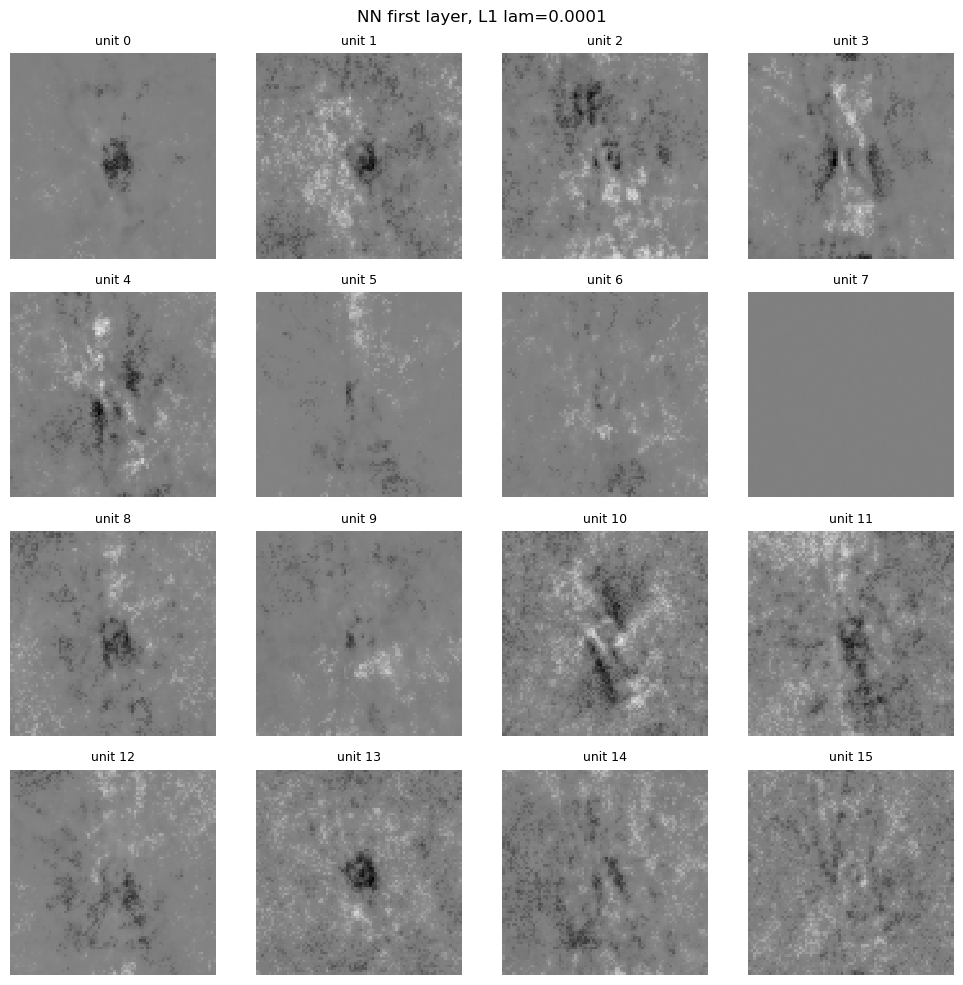

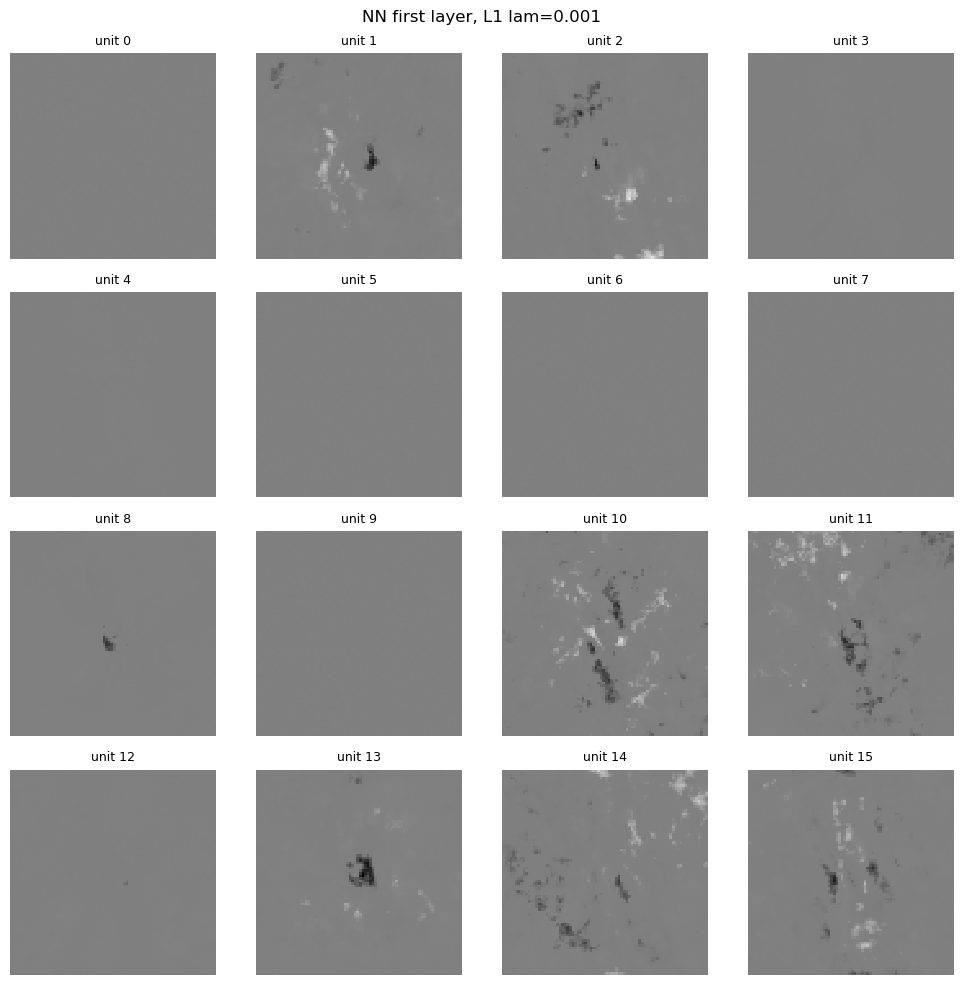

In [26]:
# YOUR CODE HERE (optional)
# ---------- 1) Logistic Regression with L1 ----------
d_rows = []
for C in [0.1, 0.02, 0.005]:
    lr1 = LogisticRegression(solver="liblinear", penalty="l1", C=C).fit(X_train_s, y_train)
    val = lr1.score(X_val_s, y_val)
    nonzero = np.mean(lr1.coef_ != 0)
    print("LR L1 C={}: val acc={:.4f}, nonzero weights={:.2%}".format(C, val, nonzero))
    d_rows.append(dict(model="LR L1", setting="C={}".format(C), val_acc=val, nonzero=nonzero))
    helper.showWeights(lr1.coef_[0], titles=["LR L1, C={}".format(C)]);

# ---------- 2) Network [16] with L1 on the first layer only ----------
def train_l1(lam, seed=SEED):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    reg = keras.regularizers.l1(float(lam)) if lam > 0 else None   # lam=0 -> no penalty (baseline)
    model = keras.Sequential([
        keras.Input(shape=(6400,)),
        layers.Dense(16, activation="relu", kernel_regularizer=reg),
        layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss="binary_crossentropy", metrics=["accuracy"])
    model.fit(X_train_s, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=0)
    return model

for lam in [0.0, 1e-5, 1e-4, 1e-3]:
    m = train_l1(lam)
    W1 = m.layers[0].get_weights()[0]                  # shape (6400, 16)
    val = accuracy(m, X_val_s, y_val)
    small = np.mean(np.abs(W1) < 1e-3)
    print("NN L1 lam={}: val acc={:.4f}, |w|<0.001: {:.2%}".format(lam, val, small))
    d_rows.append(dict(model="NN [16] L1", setting="lam={}".format(lam), val_acc=val, small_weights=small))
    helper.showWeights(W1, shared_scale=True, suptitle="NN first layer, L1 lam={}".format(lam));

# ---------- 3) Summary table ----------
display(pd.DataFrame(d_rows).round(4))

YOUR ANSWER HERE
- Readability: L1 removes much of the background speckle, but very sparse maps can become scattered pixels rather than recognizable patterns.
      - As L1 increases, Many become images with a full gray background; previously visible (from previous options) cannot be seen 
- Logistic Regression: Mild L1 improves validation accuracy from 85.50% to 88.00%. Strong L1 reduces it to 81.25%.
- Network: $\lambda=10^{-5}$ increases sparsity without changing validation accuracy in this run. Stronger penalties reduce accuracy by 2.25–2.50 percentage points.
- Uncertainty: These regularization comparisons use one seed, so repeated runs would help establish whether the differences persist.
- Conclusion: Cleaner weights do not guarantee better predictions. Sparsity may help interpretation, but validation performance must be checked separately.

## Optional E: Your own experiments

Anything you are curious about. Some ideas: keep the three color channels instead of gray-scale; try another hidden activation; add dropout; flip or rotate the training images as extra training examples; change the optimizer or learning rate; look at the images the best network gets wrong (error analysis).

For each experiment state a **hypothesis**, change **one thing**, compare with a baseline **while taking the noise into account**, and write a short paragraph on what you found.

training examples: baseline=3200, augmented=9600


Text(0.5, 1.0, 'original')

Text(0.5, 1.0, 'left-right flip')

Text(0.5, 1.0, 'up-down flip')

Text(0.5, 0.98, 'Optional E: augmented training examples')

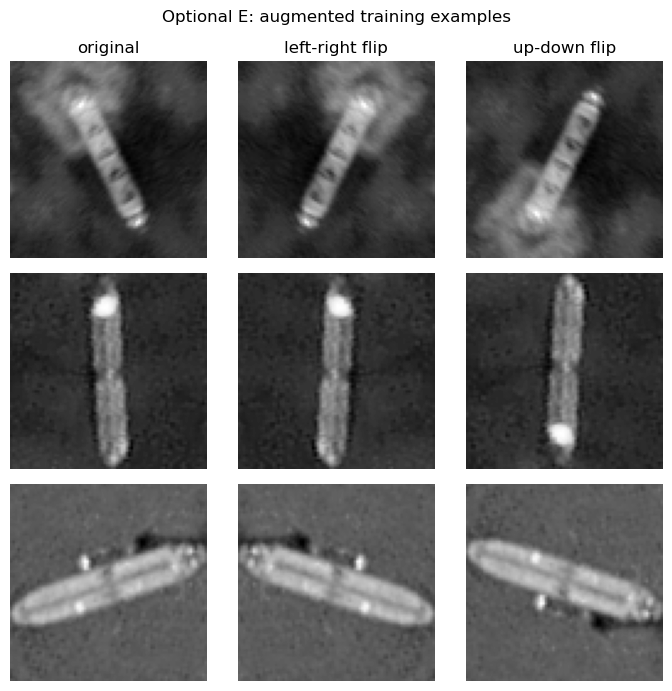

baseline seed 0 done
baseline seed 1 done
baseline seed 2 done
flip aug seed 0 done
flip aug seed 1 done
flip aug seed 2 done


,data,seed,train_acc,val_acc,seconds
0,baseline,0,1.0000,0.9675,5
1,baseline,1,0.9981,0.9475,5
2,baseline,2,0.9741,0.9450,4
3,flip aug,0,1.0000,0.9750,14
4,flip aug,1,0.9997,0.9625,14
5,flip aug,2,0.9988,0.9625,13


,train_mean,val_mean,val_std,seconds_mean
data,,,,
baseline,0.9907,0.9533,0.0123,4.6667
flip aug,0.9995,0.9667,0.0072,13.6667


flip aug - baseline = +1.33 points (noise guideline: about 1.5 points)


<BarContainer object of 2 artists>

...

Text(0, 0.5, 'validation accuracy')

Text(0.5, 1.0, 'Mean ± SD over 3 seeds (dots = seeds)')

Text(0.5, 0, 'epoch')

Text(0, 0.5, 'accuracy')

Text(0.5, 1.0, 'Learning curves (seed 0)')

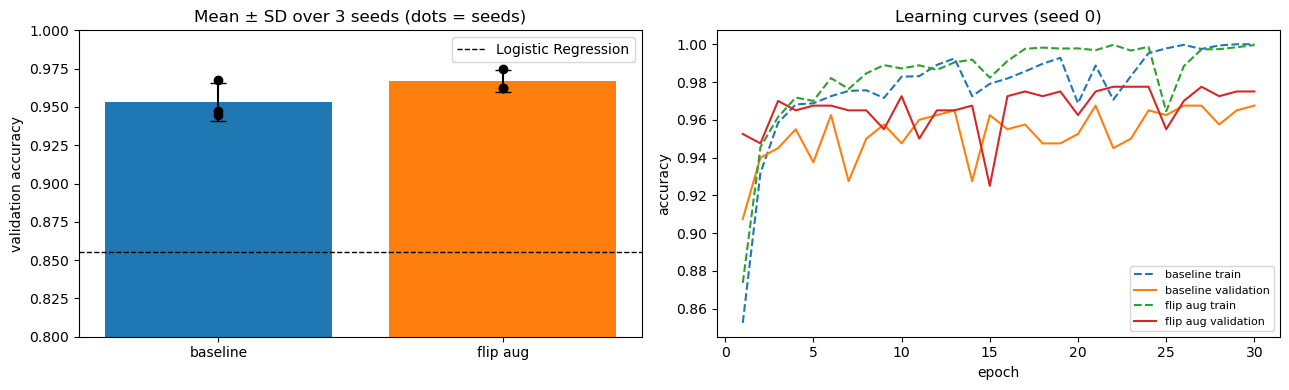

Text(0, 0, '291')

Text(1, 0, '8')

Text(0, 1, '5')

Text(1, 1, '96')

Text(0.5, 0, 'predicted')

...

Text(1, 1, '95')

Text(0.5, 0, 'predicted')

Text(0, 0.5, 'true')

Text(0.5, 1.0, 'flip aug (seed 0)')

Text(0.5, 0.98, 'Confusion matrices on the validation set')

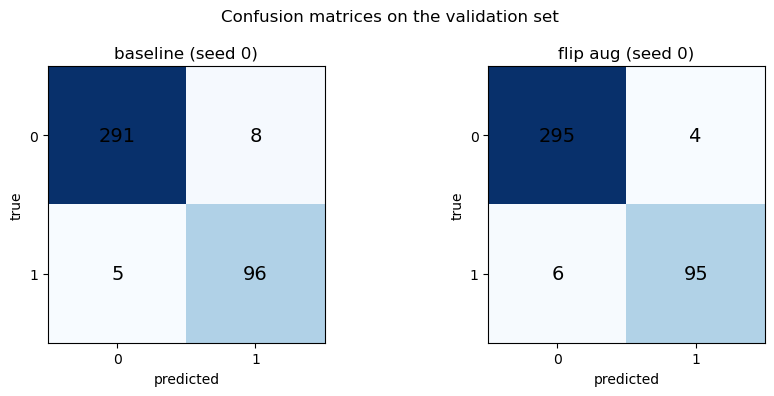

flip-aug model, seed 0: 10 validation errors


Text(0.5, 0.98, 'Misclassified validation images (flip-aug model)')

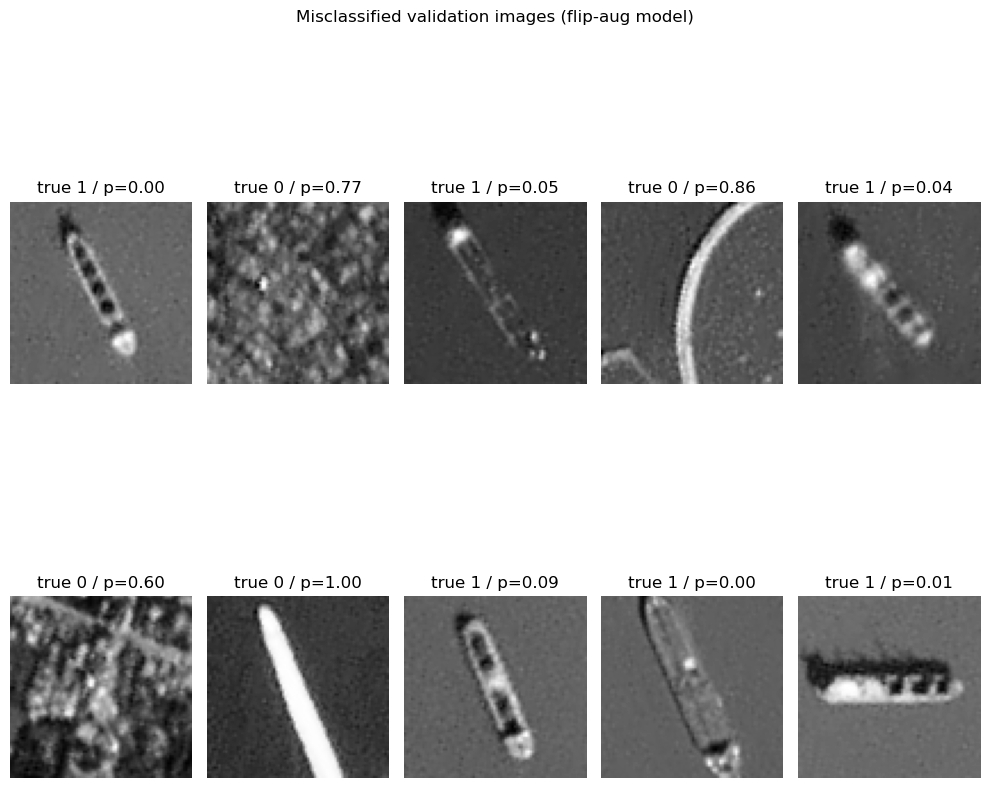

In [27]:
# YOUR CODE HERE (optional)
# ===== Optional E: does flip augmentation help? =====
# Hypothesis: a flipped ship is still a ship, so adding flipped copies of the training
# images should help the network generalize. One change: the training data (original + 2 flips).
# Baseline: the same L=1, width-16 network on the original data. Same 3 seeds for both.
from sklearn.metrics import confusion_matrix

# ---- 1) Build the augmented training set ----
imgs = X_train.reshape(-1, 80, 80)
X_aug = np.concatenate([imgs, imgs[:, :, ::-1], imgs[:, ::-1, :]]).reshape(-1, 6400)
y_aug = np.concatenate([y_train] * 3)
X_aug_s = scaler.transform(X_aug).astype("float32")      # same scaler (fit on the original training set)
print("training examples: baseline={}, augmented={}".format(len(y_train), len(y_aug)))

# Picture: what the augmentation does (3 ships: original / left-right / up-down)
ship_idx = np.where(y_train == 1)[0][:3]
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for r, i in enumerate(ship_idx):
    for c, (img, t) in enumerate([(imgs[i], "original"), (imgs[i][:, ::-1], "left-right flip"),
                                  (imgs[i][::-1, :], "up-down flip")]):
        axes[r, c].imshow(img, cmap="gray"); axes[r, c].set_axis_off()
        if r == 0: axes[r, c].set_title(t)
fig.suptitle("Optional E: augmented training examples"); fig.tight_layout(); plt.show()

# ---- 2) Train baseline and augmented models, 3 seeds each ----
def train_on(Xtr, ytr, hw, seed):
    keras.backend.clear_session(); keras.utils.set_random_seed(seed)
    m = build_model(hw)
    h = m.fit(Xtr, ytr, epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=0,
              validation_data=(X_val_s, y_val))           # only to record the learning curve
    return m, h.history

rows_e, hist, models = [], {}, {}
for name, (Xtr, ytr) in {"baseline": (X_train_s, y_train), "flip aug": (X_aug_s, y_aug)}.items():
    for s in [0, 1, 2]:
        t0 = time.time()
        m, h = train_on(Xtr, ytr, [16], s)
        rows_e.append(dict(data=name, seed=s, train_acc=accuracy(m, X_train_s, y_train),
                           val_acc=accuracy(m, X_val_s, y_val), seconds=round(time.time() - t0)))
        if s == 0:
            hist[name], models[name] = h, m
        print(name, "seed", s, "done")

# ---- 3) Tables ----
runs_e = pd.DataFrame(rows_e)
display(runs_e.round(4))
summary_e = runs_e.groupby("data", sort=False).agg(
    train_mean=("train_acc", "mean"), val_mean=("val_acc", "mean"),
    val_std=("val_acc", "std"), seconds_mean=("seconds", "mean"))
display(summary_e.round(4))
diff = summary_e.loc["flip aug", "val_mean"] - summary_e.loc["baseline", "val_mean"]
print("flip aug - baseline = {:+.2f} points (noise guideline: about 1.5 points)".format(100 * diff))

# ---- 4) Graphs: bar chart + learning curves ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = list(summary_e.index)
axes[0].bar(names, summary_e["val_mean"], yerr=summary_e["val_std"], capsize=6, color=["tab:blue", "tab:orange"])
for i, n in enumerate(names):
    axes[0].scatter([i] * 3, runs_e[runs_e.data == n]["val_acc"], color="k", zorder=3)
axes[0].axhline(lr_val_acc, color="k", ls="--", lw=1, label="Logistic Regression")
axes[0].set_ylim(0.80, 1.0); axes[0].set_ylabel("validation accuracy")
axes[0].set_title("Mean ± SD over 3 seeds (dots = seeds)"); axes[0].legend()
for n in names:
    axes[1].plot(range(1, EPOCHS + 1), hist[n]["accuracy"], ls="--", label=n + " train")
    axes[1].plot(range(1, EPOCHS + 1), hist[n]["val_accuracy"], label=n + " validation")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Learning curves (seed 0)"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

# ---- 5) Error analysis: confusion matrices + misclassified validation images ----
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, n in zip(axes, names):
    pred = (np.asarray(models[n](X_val_s, training=False)).ravel() > 0.5).astype(int)
    cm = confusion_matrix(y_val, pred)
    ax.imshow(cm, cmap="Blues")
    for (r, c), v in np.ndenumerate(cm):
        ax.text(c, r, v, ha="center", va="center", fontsize=14)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(n + " (seed 0)")
fig.suptitle("Confusion matrices on the validation set"); fig.tight_layout(); plt.show()

p_aug = np.asarray(models["flip aug"](X_val_s, training=False)).ravel()
wrong = np.where((p_aug > 0.5) != y_val)[0]
print("flip-aug model, seed 0: {} validation errors".format(len(wrong)))
show = wrong[:15]
fig = helper.showData(X_val[show].reshape(-1, 80, 80),
                      ["true {} / p={:.2f}".format(y_val[i], p_aug[i]) for i in show], cmap="gray")
fig.suptitle("Misclassified validation images (flip-aug model)"); plt.show()

**Optional E: Flip augmentation**

- **Hypothesis:** Left-right and up-down flips preserve the ship/no-ship label, so adding flipped images may improve generalization.
- **Change:** Expand the training set from **3,200 to 9,600 images** (originals + two flipped copies)
- **Fixed settings:**
    * Network: L=1, width 16, with the same recipe.
    * Seeds: 0, 1 and 2.
    * Scaler: fit on the original training set.
    * Evaluation: the same 400 validation images.

| Model | Validation seed 0 | Seed 1 | Seed 2 | Mean | Sample SD |
|---|---:|---:|---:|---:|---:|
| Baseline | 96.75% | 94.75% | 94.50% | 95.33% | 1.23 points |
| Flip augmentation | 97.50% | 96.25% | 96.25% | 96.67% | 0.72 points |

- **Result:** Augmentation improves every seed by **0.75, 1.50, and 1.75 percentage points**.
- **Mean gain:** **1.33 percentage points**, with less variation across seeds.
- **Interpretation:** This is consistent preliminary evidence of a small improvement. However, the mean gain is below the assignment’s 1.5-point noise guideline, and three seeds provide limited evidence.

**Error analysis — seed 0**

- Baseline: **13 errors** — 8 false positives and 5 missed ships.
- Augmented: **10 errors** — 4 false positives and 6 missed ships.
- Augmentation reduces false alarms but misses one additional ship.
- The missed examples suggest possible difficulty with long, segmented, diagonal, or partly cropped ships. This is a hypothesis, not proof of what the model learned.
- Some false positives contain ship-like shapes or textures; closer inspection would help explain these mistakes.

**Limitation and next steps**

- Augmentation makes **4,500 gradient updates**, versus **1,500** for the baseline. Some improvement could come from extra optimization rather than the flips.
- Training the baseline for **90 epochs** would match the update count and provide a useful control.
- Another experiment could test rotations across additional angles. A 90° rotation alone keeps diagonal ships diagonal.
- The test set was not used in these experiments.

# Done

In [28]:
print("Done")

Done
